<div style="border:2px solid #2e7d32; border-radius:10px; padding:14px; background:#f1f8e9">

# 🌸 CNN From Scratch: Flower Classification (Underfitting → Overfitting → Good Fit)


</div>

In this project I train **Convolutional Neural Networks from scratch** (no pretrained weights at all) to classify
photos of flowers into 5 classes using PyTorch.

The main goal is not only to get a good accuracy, but to **diagnose and fix the two classic training problems**:

| Problem | What it means | Symptom on the curves |
|---|---|---|
| **Underfitting** (high bias) | the model is too weak to learn even the training data | train accuracy is low, train & val curves are both bad and close to each other |
| **Overfitting** (high variance) | the model memorises the training images instead of learning general patterns | train accuracy → ~100%, val accuracy stops improving, **val loss goes up** |

**Plan (the story of the notebook):**
1. Explore the dataset
2. Prepare the data (split, normalisation computed from *our* data, augmentation)
3. **Model 1 – Tiny CNN →** we show **underfitting**
4. **Fix underfitting** by adding capacity → **Model 2 – Big CNN (no regularisation) →** now it **overfits**
5. **Fix overfitting** → **Model 3 – Regularised CNN** (augmentation, BatchNorm, Dropout, Global Avg Pooling, weight decay, label smoothing, LR scheduler, early stopping)
6. Compare the 3 models on a held-out **test set**
7. Look inside the CNN: learned filters, feature maps, Grad-CAM, and the mistakes it makes

**Dataset:** [TensorFlow Flowers](https://www.tensorflow.org/datasets/catalog/tf_flowers) — 3,670 real RGB photos of
different sizes, 5 classes: *daisy, dandelion, roses, sunflowers, tulips*.
It is a **small** dataset of **real, messy photos**, which makes it a perfect playground for overfitting when training from scratch.

## 1. Imports & setup

In [1]:
import os, time, copy, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import v2
from torchvision.datasets.utils import download_and_extract_archive
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("PyTorch:", torch.__version__)

Using device: cpu
PyTorch: 2.15.0+cu132


## 2. Download and explore the dataset
The archive is downloaded once (~220 MB) and every class is a folder, so `ImageFolder` can read it directly.

In [2]:
DATA_DIR = "./data"
URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
if not os.path.isdir(os.path.join(DATA_DIR, "flower_photos")):
    download_and_extract_archive(URL, DATA_DIR)

raw_data = datasets.ImageFolder(os.path.join(DATA_DIR, "flower_photos"))   # PIL images, no transform
class_names = raw_data.classes
NUM_CLASSES = len(class_names)
targets = np.array(raw_data.targets)

print("Number of images:", len(raw_data))
print("Classes:", class_names)

Number of images: 3670
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


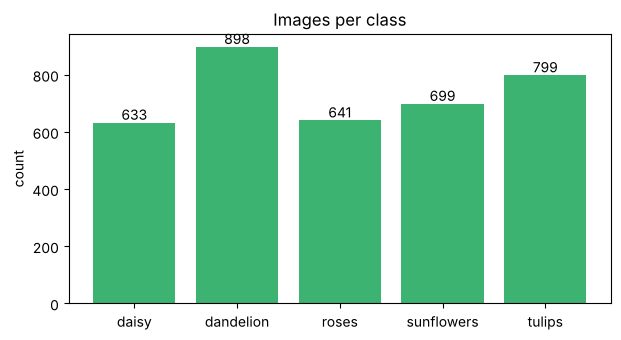

Width  min/median/max: 145 320 640
Height min/median/max: 177 240 411


In [3]:
# How many images per class? (is the dataset balanced?)
counts = np.bincount(targets)
plt.figure(figsize=(7, 3.5))
plt.bar(class_names, counts, color="mediumseagreen")
for i, c in enumerate(counts):
    plt.text(i, c + 10, str(c), ha="center")
plt.title("Images per class")
plt.ylabel("count")
plt.show()

# The photos have different sizes -> we will have to resize them
sizes = np.array([raw_data[i][0].size for i in range(0, len(raw_data), 10)])
print("Width  min/median/max:", sizes[:, 0].min(), int(np.median(sizes[:, 0])), sizes[:, 0].max())
print("Height min/median/max:", sizes[:, 1].min(), int(np.median(sizes[:, 1])), sizes[:, 1].max())

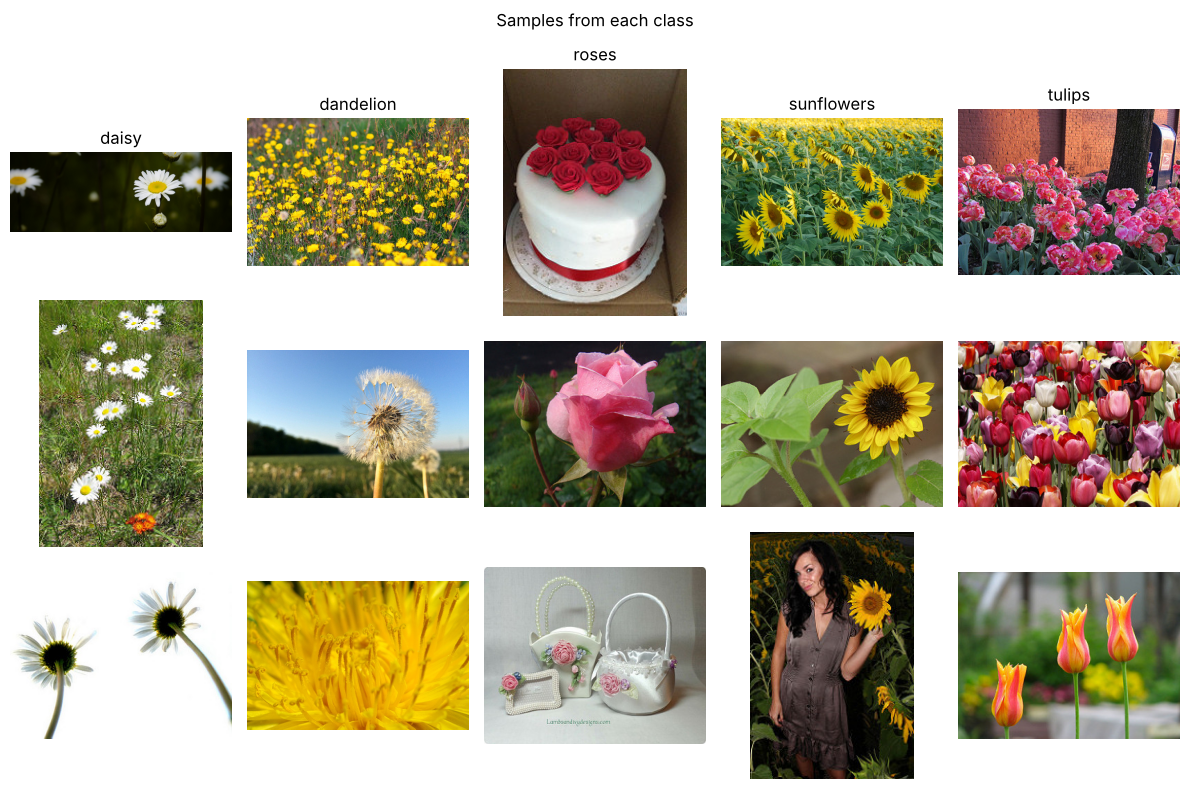

In [4]:
# show 3 random images from each class
plt.figure(figsize=(12, 8))
rng = np.random.default_rng(0)
for c, name in enumerate(class_names):
    idxs = rng.choice(np.where(targets == c)[0], 3, replace=False)
    for k, idx in enumerate(idxs):
        plt.subplot(3, NUM_CLASSES, k * NUM_CLASSES + c + 1)
        plt.imshow(raw_data[idx][0])
        plt.axis("off")
        if k == 0:
            plt.title(name)
plt.suptitle("Samples from each class")
plt.tight_layout()
plt.show()

**Observations**
- The classes are only slightly imbalanced (633 → 898), so plain accuracy is OK, but I will also look at per-class precision/recall.
- Images have very different sizes and aspect ratios → resize everything to a fixed size.
- Only ~730 images per class. A CNN with millions of parameters can easily **memorise** that → we expect overfitting.
- **Colour is a very important feature** here (yellow sunflowers / dandelions, red roses...). So in augmentation I will
  **not** change the *hue*, otherwise a red rose could become a yellow one and I would destroy the label information.

## 3. Prepare the data

1. **Stratified split** 70% train / 15% validation / 15% test (every split has the same class proportions).
   - *train*: to update the weights
   - *validation*: to monitor over/underfitting, choose hyper-parameters and do early stopping
   - *test*: touched **only once at the end** for a fair comparison
2. Resize all images to **96×96** and keep them in memory as a `uint8` tensor (fast training on CPU).
3. **Normalisation**: because we train *from scratch*, there is no reason to use the ImageNet mean/std.
   I compute the mean and std of **our own training set** (only train, to avoid data leakage).
4. Two pipelines:
   - **basic** (eval): just convert to float + normalise
   - **augmented** (train for Model 3): random crop & zoom, horizontal flip, small rotation, brightness/contrast/saturation jitter

In [5]:
IMG_SIZE = 96

idx_all = np.arange(len(raw_data))
train_idx, temp_idx = train_test_split(idx_all, test_size=0.30, stratify=targets, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=targets[temp_idx], random_state=SEED)
print("Train:", len(train_idx), "| Val:", len(val_idx), "| Test:", len(test_idx))

# load + resize every image once and keep it in memory (uint8: 3670*3*96*96 ≈ 100 MB)
resize = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.PILToTensor()])
t0 = time.time()
all_images = torch.stack([resize(raw_data[i][0].convert("RGB")) for i in range(len(raw_data))])
all_labels = torch.tensor(targets)
print("Images tensor:", tuple(all_images.shape), all_images.dtype, f"(loaded in {time.time()-t0:.1f}s)")

# mean / std computed on the TRAINING images only
train_float = all_images[train_idx].float() / 255.0
MEAN = train_float.mean(dim=(0, 2, 3)).tolist()
STD = train_float.std(dim=(0, 2, 3)).tolist()
del train_float
print("Train mean:", [round(m, 3) for m in MEAN], " std:", [round(s, 3) for s in STD])

Train: 2569 | Val: 550 | Test: 551


Images tensor: (3670, 3, 96, 96) torch.uint8 (loaded in 5.1s)


Train mean: [0.466, 0.425, 0.306]  std: [0.29, 0.261, 0.285]


In [6]:
basic_transform = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])

aug_transform = v2.Compose([
    v2.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.8, 1.25), antialias=True),  # random zoom / crop
    v2.RandomHorizontalFlip(),                                                            # a flower mirrored is still the same flower
    v2.RandomRotation(15),
    v2.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25),                      # NO hue change (colour = label info!)
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])


class FlowerTensorDataset(Dataset):
    # images are already resized uint8 tensors -> transforms run directly on tensors (fast)
    def __init__(self, indices, transform):
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        return self.transform(all_images[j]), all_labels[j]


BATCH = 64
g = torch.Generator().manual_seed(SEED)
train_loader_basic = DataLoader(FlowerTensorDataset(train_idx, basic_transform), batch_size=BATCH, shuffle=True, generator=g)
train_loader_aug   = DataLoader(FlowerTensorDataset(train_idx, aug_transform),   batch_size=BATCH, shuffle=True, generator=g)
train_eval_loader  = DataLoader(FlowerTensorDataset(train_idx, basic_transform), batch_size=256)   # clean train accuracy
val_loader         = DataLoader(FlowerTensorDataset(val_idx, basic_transform),   batch_size=256)
test_loader        = DataLoader(FlowerTensorDataset(test_idx, basic_transform),  batch_size=256)

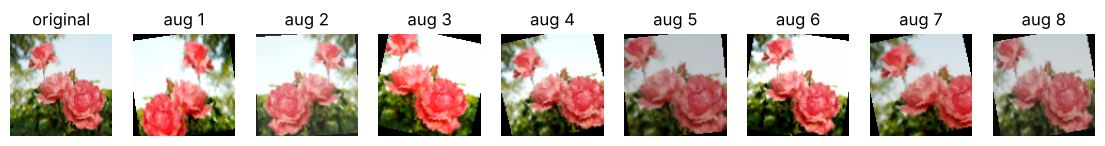

In [7]:
# what does augmentation actually do? same image, 8 random augmented versions
def denorm(t):
    img = t.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    return np.clip(img, 0, 1)

sample = all_images[train_idx[7]]
plt.figure(figsize=(14, 2.6))
plt.subplot(1, 9, 1); plt.imshow(denorm(basic_transform(sample))); plt.title("original"); plt.axis("off")
for k in range(8):
    plt.subplot(1, 9, k + 2); plt.imshow(denorm(aug_transform(sample))); plt.title(f"aug {k+1}"); plt.axis("off")
plt.show()

## 4. Helper functions

- `train_model`: a full training loop that also supports **weight decay, label smoothing, an LR scheduler and early stopping**
  (with restoring the best weights).
- An important detail: when using augmentation + dropout, the accuracy measured *during* training is computed on
  distorted images with neurons switched off, so it is **lower than the real training accuracy**. That can hide overfitting
  (you can even get *train acc < val acc*). So after every epoch I also measure a **clean training accuracy**
  (eval mode, no augmentation) and use **that** to compute the train/val gap. This makes the diagnosis honest.
- `diagnose_fit`: decides automatically if a model is underfitting, overfitting or well fitted, and explains why.

In [8]:
def evaluate(model, loader, loss_fn=None):
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, epochs, lr, weight_decay=0.0,
                label_smoothing=0.0, use_scheduler=False, patience=None, verbose_every=1):
    model = model.to(device)
    train_loss_fn = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    eval_loss_fn = nn.CrossEntropyLoss()                      # val loss always measured the same way -> comparable
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = (optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, epochs=epochs,
                                               steps_per_epoch=len(train_loader))
                 if use_scheduler else None)

    history = {k: [] for k in ["train_loss", "train_acc", "train_clean_acc", "val_loss", "val_acc", "lr"]}
    best_val_loss, best_state, best_epoch, bad_epochs = float("inf"), None, 0, 0
    start = time.time()

    for epoch in range(epochs):
        # ---------- training ----------
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = train_loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()
            if scheduler: scheduler.step()
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        # ---------- measuring ----------
        _, train_clean_acc = evaluate(model, train_eval_loader, eval_loss_fn)
        val_loss, val_acc = evaluate(model, val_loader, eval_loss_fn)
        history["train_loss"].append(total_loss / total)
        history["train_acc"].append(correct / total)
        history["train_clean_acc"].append(train_clean_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        # ---------- early stopping bookkeeping ----------
        if val_loss < best_val_loss - 1e-4:
            best_val_loss, best_epoch, bad_epochs = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epochs += 1

        if (epoch + 1) % verbose_every == 0 or epoch == 0:
            print(f"Epoch {epoch+1:2d}/{epochs} | train loss {total_loss/total:.3f} acc {correct/total:.3f} "
                  f"(clean {train_clean_acc:.3f}) | val loss {val_loss:.3f} acc {val_acc:.3f}")

        if patience is not None and bad_epochs >= patience:
            print(f"⏹ Early stopping at epoch {epoch+1}: val loss did not improve for {patience} epochs.")
            break

    history["best_epoch"] = best_epoch
    if patience is not None and best_state is not None:
        model.load_state_dict(best_state)
        print(f"↩ Restored best weights from epoch {best_epoch+1} (val loss {best_val_loss:.3f})")
    print(f"Training time: {time.time()-start:.0f}s")
    return history


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def plot_history(history, title):
    ep = np.arange(1, len(history["val_loss"]) + 1)
    plt.figure(figsize=(13, 4))
    plt.subplot(1, 2, 1)
    plt.plot(ep, history["train_loss"], label="train")
    plt.plot(ep, history["val_loss"], label="validation")
    b = history["best_epoch"] + 1
    plt.axvline(b, color="gray", ls="--", lw=1, label=f"min val loss (epoch {b})")
    plt.title(title + " – Loss"); plt.xlabel("Epoch"); plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(ep, history["train_acc"], label="train (augmented / dropout on)", alpha=0.6)
    plt.plot(ep, history["train_clean_acc"], label="train (clean, eval mode)")
    plt.plot(ep, history["val_acc"], label="validation")
    plt.title(title + " – Accuracy"); plt.xlabel("Epoch"); plt.ylim(0, 1.02); plt.legend()
    plt.show()


def diagnose_fit(history, name):
    tr = history["train_clean_acc"][-1]
    va = history["val_acc"][-1]
    gap = tr - va
    min_vl = min(history["val_loss"])
    last_vl = history["val_loss"][-1]
    rise = (last_vl - min_vl) / min_vl          # how much val loss went UP after its best point
    print(f"[{name}] final clean train acc = {tr:.3f} | val acc = {va:.3f} | gap = {gap:+.3f} | "
          f"val loss: best {min_vl:.3f} → last {last_vl:.3f} ({rise:+.0%})")
    if tr < 0.75:
        verdict = "UNDERFITTING ❌ – the model can't even learn the training data (high bias)."
    elif gap > 0.10 or rise > 0.25:
        verdict = "OVERFITTING ❌ – it memorises the training set; val loss rises / big train-val gap (high variance)."
    else:
        verdict = "GOOD FIT ✅ – high train accuracy, small gap, and the val loss did not blow up."
    print("→", verdict)
    return verdict

## 5. Model 1 – Tiny CNN (to demonstrate **underfitting**)

A deliberately weak CNN: only **2 convolution layers with 8 and 16 filters**, aggressive downsampling (stride 2 + max pooling)
and global average pooling. It has only a few thousand parameters, so it does not have enough **capacity** to represent the
differences between 5 kinds of flowers.

In [9]:
class TinyCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=5, stride=2, padding=2), nn.ReLU(), nn.MaxPool2d(4),   # 96 -> 48 -> 12
            nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),                                                         # 16 numbers per image
        )
        self.classifier = nn.Linear(16, num_classes)

    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))

set_seed()
model1 = TinyCNN()
print("Model 1 trainable parameters:", f"{count_params(model1):,}")
history1 = train_model(model1, train_loader_basic, val_loader, epochs=20, lr=1e-3, verbose_every=2)

Model 1 trainable parameters: 1,861


Epoch  1/20 | train loss 1.570 acc 0.263 (clean 0.319) | val loss 1.484 acc 0.333


Epoch  2/20 | train loss 1.398 acc 0.394 (clean 0.419) | val loss 1.340 acc 0.431


Epoch  4/20 | train loss 1.221 acc 0.475 (clean 0.469) | val loss 1.220 acc 0.476


Epoch  6/20 | train loss 1.189 acc 0.485 (clean 0.478) | val loss 1.213 acc 0.504


Epoch  8/20 | train loss 1.166 acc 0.495 (clean 0.515) | val loss 1.186 acc 0.516


... (2 outputs left out)

Epoch 14/20 | train loss 1.112 acc 0.529 (clean 0.543) | val loss 1.130 acc 0.555


Epoch 16/20 | train loss 1.089 acc 0.554 (clean 0.574) | val loss 1.114 acc 0.558


Epoch 18/20 | train loss 1.069 acc 0.566 (clean 0.576) | val loss 1.091 acc 0.571


Epoch 20/20 | train loss 1.051 acc 0.577 (clean 0.567) | val loss 1.088 acc 0.558
Training time: 19s


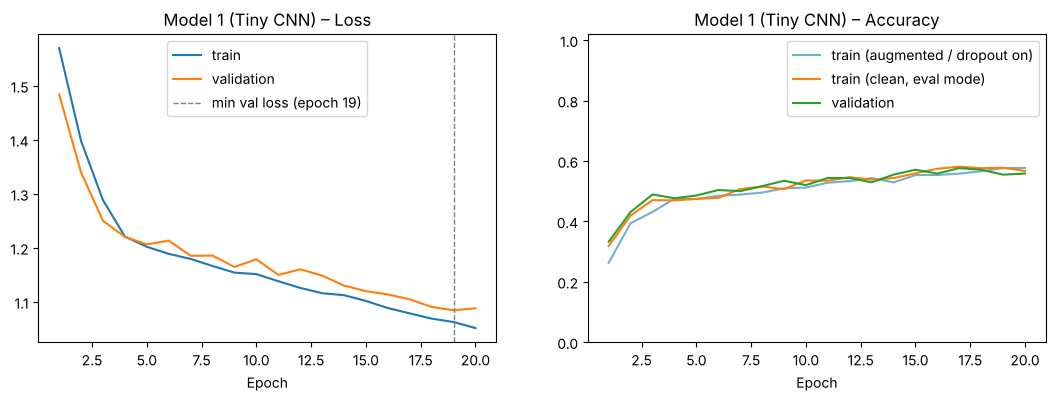

[Model 1] final clean train acc = 0.567 | val acc = 0.558 | gap = +0.009 | val loss: best 1.084 → last 1.088 (+0%)
→ UNDERFITTING ❌ – the model can't even learn the training data (high bias).


In [10]:
plot_history(history1, "Model 1 (Tiny CNN)")
verdict1 = diagnose_fit(history1, "Model 1")

### Diagnosis: Model 1 is **underfitting**
- The **training** accuracy itself is low: the model fails on images it has already seen many times.
- Train and validation curves stay **close together and both are bad**, so the problem is not memorisation, it is that the
  model is **too simple** (high bias).
- Regularisation (dropout, augmentation...) would make it **worse** here, because those methods make learning *harder*.

### ✅ How to fix underfitting
1. **Increase capacity**: more convolution layers and more filters per layer (deeper + wider network).
2. Keep more spatial information (less aggressive downsampling, 3×3 kernels with `padding=1`).
3. A bigger fully-connected head.
4. Train for more epochs.

→ That is exactly what I do in Model 2.

## 6. Model 2 – Big CNN, no regularisation (underfitting fixed → but now **overfitting**)

4 convolution blocks (32 → 64 → 128 → 256 filters), each block: `Conv 3×3 → ReLU → MaxPool 2×2`, then **Flatten** and a big
fully-connected layer (512 neurons). No augmentation, no dropout, no batch norm, no weight decay.

In [11]:
class BigCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        def block(cin, cout):
            return [nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(
            *block(3, 32),     # 96 -> 48
            *block(32, 64),    # 48 -> 24
            *block(64, 128),   # 24 -> 12
            *block(128, 256),  # 12 -> 6
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 6 * 6, 512), nn.ReLU(),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

set_seed()
model2 = BigCNN()
print("Model 2 trainable parameters:", f"{count_params(model2):,}",
      f"(~{count_params(model2)/len(train_idx):,.0f} parameters per training image!)")
history2 = train_model(model2, train_loader_basic, val_loader, epochs=25, lr=1e-3, verbose_every=1)

Model 2 trainable parameters: 5,110,085 (~1,989 parameters per training image!)


Epoch  1/25 | train loss 1.376 acc 0.382 (clean 0.499) | val loss 1.188 acc 0.518


Epoch  2/25 | train loss 1.052 acc 0.576 (clean 0.628) | val loss 0.977 acc 0.620


Epoch  3/25 | train loss 0.854 acc 0.653 (clean 0.696) | val loss 0.905 acc 0.656


Epoch  4/25 | train loss 0.770 acc 0.692 (clean 0.723) | val loss 0.859 acc 0.656


Epoch  5/25 | train loss 0.709 acc 0.719 (clean 0.715) | val loss 0.973 acc 0.649


... (16 outputs left out)

Epoch 22/25 | train loss 0.055 acc 0.984 (clean 0.984) | val loss 2.057 acc 0.685


Epoch 23/25 | train loss 0.040 acc 0.988 (clean 0.993) | val loss 1.842 acc 0.720


Epoch 24/25 | train loss 0.029 acc 0.991 (clean 0.996) | val loss 1.851 acc 0.727


Epoch 25/25 | train loss 0.023 acc 0.995 (clean 0.998) | val loss 1.880 acc 0.729
Training time: 522s


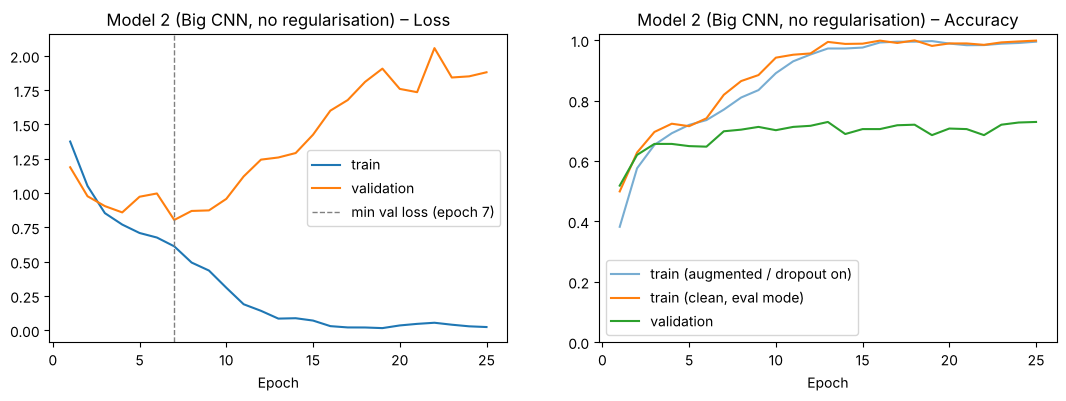

[Model 2] final clean train acc = 0.998 | val acc = 0.729 | gap = +0.269 | val loss: best 0.804 → last 1.880 (+134%)
→ OVERFITTING ❌ – it memorises the training set; val loss rises / big train-val gap (high variance).


In [12]:
plot_history(history2, "Model 2 (Big CNN, no regularisation)")
verdict2 = diagnose_fit(history2, "Model 2")

### Diagnosis: underfitting is solved, but Model 2 is now **overfitting**
- **Underfitting fixed ✅**: the clean training accuracy goes very high (close to 100%) – the network now has enough capacity.
- **But** look at the loss plot: the validation loss reaches its minimum after a few epochs (dashed line) and then
  **goes up again**, while the training loss keeps going down to ~0. The validation accuracy stops improving.
- The train–validation gap is huge. The model has millions of parameters for only ~2,500 training images, so it simply
  **memorises** the training photos (backgrounds, exact pixels...) instead of learning what a "tulip" looks like.
- Most of the parameters are in the `Flatten → Linear(9216, 512)` layer: that layer is the easiest place to memorise.

### ✅ How to fix overfitting (what I do in Model 3)
| # | Technique | Why it helps |
|---|---|---|
| 1 | **Data augmentation** (random crop/zoom, flip, rotation, colour jitter without hue) | every epoch the model sees *new* versions of the images → harder to memorise, learns invariances |
| 2 | **Batch Normalization** after every conv | stabilises & speeds up training, has a small regularising effect |
| 3 | **Dropout** (2D dropout in conv blocks + 0.5 before the classifier) | randomly turns off neurons → no single neuron can memorise |
| 4 | **Global Average Pooling** instead of Flatten + big FC | removes ~4.7M parameters; forces the conv filters to learn "flower-part detectors" |
| 5 | **Weight decay** (AdamW, L2-style penalty) | keeps the weights small → smoother, simpler function |
| 6 | **Label smoothing** (0.1) | stops the model from being over-confident on training labels |
| 7 | **OneCycle LR scheduler** | warm-up then decreasing LR → better and more stable convergence |
| 8 | **Early stopping + restore best weights** | stop when val loss stops improving, keep the best epoch |

At the same time I keep the network **deep enough** (two convs per block) so we don't go back to underfitting.

## 7. Model 3 – Regularised CNN (the fixed model ✅)

In [13]:
class RegularizedCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        def conv_bn(cin, cout):
            return [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU()]
        self.features = nn.Sequential(
            *conv_bn(3, 32),                                  nn.MaxPool2d(2), nn.Dropout2d(0.05),  # 96 -> 48
            *conv_bn(32, 64),                                 nn.MaxPool2d(2), nn.Dropout2d(0.10),  # 48 -> 24
            *conv_bn(64, 128),  *conv_bn(128, 128),           nn.MaxPool2d(2), nn.Dropout2d(0.15),  # 24 -> 12
            *conv_bn(128, 256), *conv_bn(256, 256),           nn.MaxPool2d(2), nn.Dropout2d(0.20),  # 12 -> 6
        )
        self.pool = nn.AdaptiveAvgPool2d(1)                   # Global Average Pooling: 256 x 6 x 6 -> 256
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

set_seed()
model3 = RegularizedCNN()
print("Model 3 trainable parameters:", f"{count_params(model3):,}",
      f"(vs {count_params(model2):,} in Model 2)")
history3 = train_model(model3, train_loader_aug, val_loader, epochs=45, lr=3e-3,
                       weight_decay=5e-4, label_smoothing=0.1, use_scheduler=True,
                       patience=12, verbose_every=1)

Model 3 trainable parameters: 1,128,229 (vs 5,110,085 in Model 2)


Epoch  1/45 | train loss 1.525 acc 0.385 (clean 0.497) | val loss 1.177 acc 0.484


Epoch  2/45 | train loss 1.380 acc 0.463 (clean 0.576) | val loss 1.092 acc 0.564


Epoch  3/45 | train loss 1.313 acc 0.504 (clean 0.600) | val loss 1.046 acc 0.584


Epoch  4/45 | train loss 1.269 acc 0.526 (clean 0.585) | val loss 1.052 acc 0.585


Epoch  5/45 | train loss 1.231 acc 0.541 (clean 0.581) | val loss 1.043 acc 0.591


... (36 outputs left out)

Epoch 42/45 | train loss 0.856 acc 0.768 (clean 0.843) | val loss 0.579 acc 0.798


Epoch 43/45 | train loss 0.866 acc 0.764 (clean 0.852) | val loss 0.568 acc 0.813


Epoch 44/45 | train loss 0.857 acc 0.781 (clean 0.849) | val loss 0.570 acc 0.816


Epoch 45/45 | train loss 0.849 acc 0.784 (clean 0.850) | val loss 0.568 acc 0.811
↩ Restored best weights from epoch 45 (val loss 0.568)
Training time: 1535s


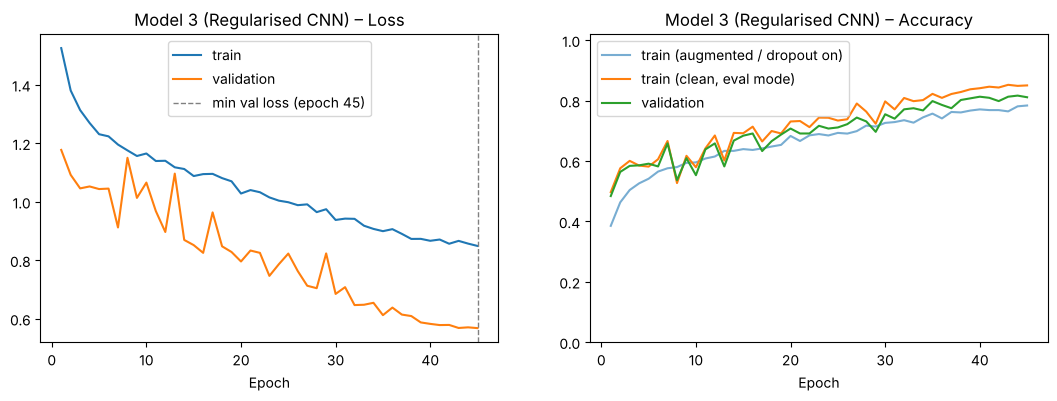

[Model 3] final clean train acc = 0.850 | val acc = 0.811 | gap = +0.039 | val loss: best 0.568 → last 0.568 (+0%)
→ GOOD FIT ✅ – high train accuracy, small gap, and the val loss did not blow up.


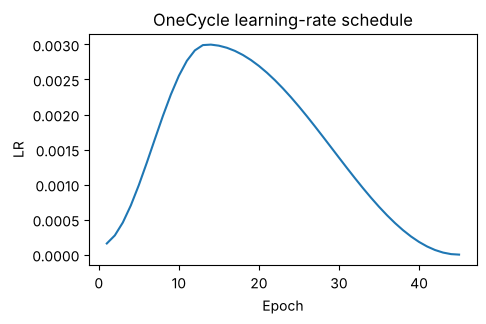

In [14]:
plot_history(history3, "Model 3 (Regularised CNN)")
verdict3 = diagnose_fit(history3, "Model 3")

plt.figure(figsize=(5, 3))
plt.plot(np.arange(1, len(history3["lr"]) + 1), history3["lr"])
plt.title("OneCycle learning-rate schedule"); plt.xlabel("Epoch"); plt.ylabel("LR")
plt.show()

### Diagnosis: Model 3 – overfitting fixed ✅
- The validation loss now **goes down together with the training loss** instead of rising after a few epochs.
- The gap between the *clean* training accuracy and the validation accuracy is small, and the validation accuracy is much
  higher than Model 2's.
- Notice how the "train (augmented / dropout on)" curve is *below* the validation curve. That is **not** a bug: the
  training images are distorted and half of the classifier neurons are dropped. This is why I track the clean train accuracy.
- The model has ~4× fewer parameters than Model 2 but performs much better: **more parameters ≠ better**, what matters
  is that the parameters are used for general features (thanks to GAP + regularisation).
- **Honest note:** the best validation loss was at the **last epoch**, which means the model was *still improving* when training
  stopped – there is no overfitting left, and if anything Model 3 is now slightly limited by the training budget
  (45 epochs on a CPU). Training longer (or at a higher resolution) would most likely push accuracy higher. Early stopping
  did not trigger, which is itself a good sign: the validation loss never started to rise.
- The validation loss is *lower* than the training loss: the training loss is computed on augmented images, with dropout on
  and with label smoothing, while the validation loss is computed on clean images in eval mode – so this is expected.


## 8. Comparing the 3 models on the **test set**
The test set was never used for training, early stopping or choosing hyper-parameters, so this is a fair comparison.

In [15]:
models_ = {"Model 1\nTiny CNN": model1, "Model 2\nBig CNN": model2, "Model 3\nRegularised CNN": model3}
histories = [history1, history2, history3]
verdicts = [verdict1, verdict2, verdict3]

results = []
for (name, m), h, v in zip(models_.items(), histories, verdicts):
    _, test_acc = evaluate(m, test_loader)
    _, train_acc = evaluate(m, train_eval_loader)
    results.append((name.replace("\n", " "), count_params(m), train_acc, test_acc, v.split(" ")[0]))

print(f"{'Model':28s}{'Params':>12s}{'Train acc':>11s}{'Test acc':>10s}{'Gap':>8s}   Diagnosis")
print("-" * 92)
for name, p, tr, te, v in results:
    print(f"{name:28s}{p:>12,d}{tr*100:>10.1f}%{te*100:>9.1f}%{(tr-te)*100:>7.1f}%   {v}")

Model                             Params  Train acc  Test acc     Gap   Diagnosis
--------------------------------------------------------------------------------------------
Model 1 Tiny CNN                   1,861      56.7%     58.6%   -1.9%   UNDERFITTING
Model 2 Big CNN                5,110,085      99.8%     72.6%   27.2%   OVERFITTING
Model 3 Regularised CNN        1,128,229      85.0%     79.9%    5.2%   GOOD


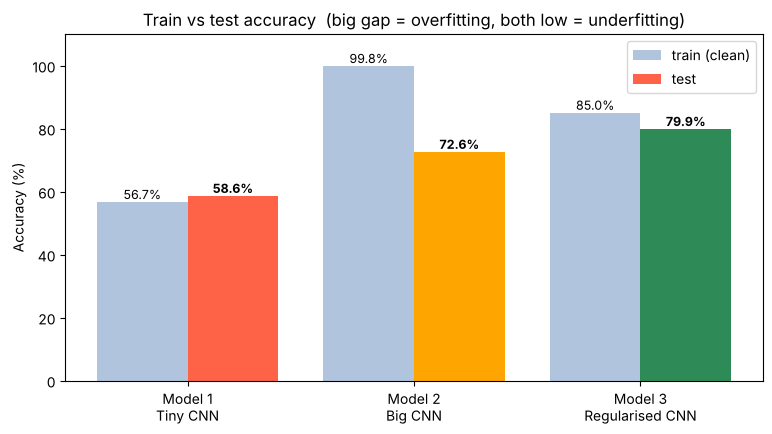

In [16]:
names = list(models_.keys())
train_accs = [r[2] * 100 for r in results]
test_accs = [r[3] * 100 for r in results]
x = np.arange(len(names))

plt.figure(figsize=(9, 4.5))
plt.bar(x - 0.2, train_accs, 0.4, label="train (clean)", color="lightsteelblue")
plt.bar(x + 0.2, test_accs, 0.4, label="test", color=["tomato", "orange", "seagreen"])
for i in range(len(names)):
    plt.text(x[i] - 0.2, train_accs[i] + 1, f"{train_accs[i]:.1f}%", ha="center", fontsize=9)
    plt.text(x[i] + 0.2, test_accs[i] + 1, f"{test_accs[i]:.1f}%", ha="center", fontsize=9, weight="bold")
plt.xticks(x, names)
plt.ylim(0, 110); plt.ylabel("Accuracy (%)")
plt.title("Train vs test accuracy  (big gap = overfitting, both low = underfitting)")
plt.legend()
plt.show()

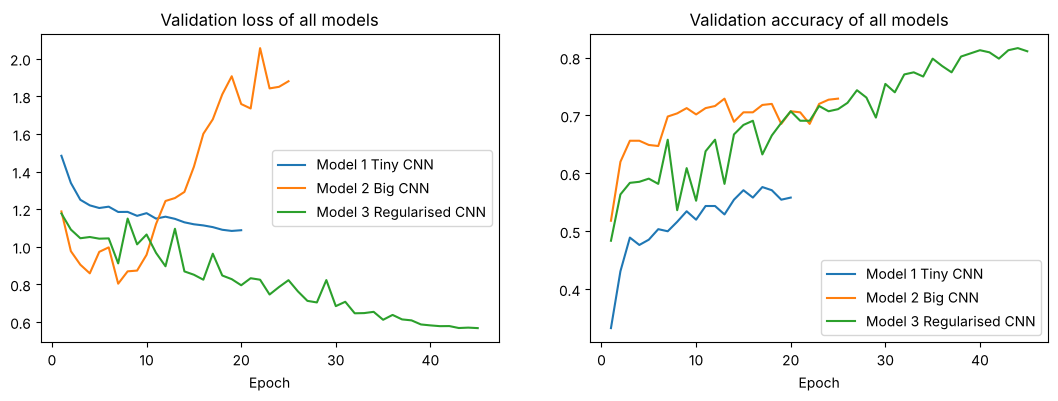

In [17]:
plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
for n, h in zip(names, histories):
    plt.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], label=n.replace("\n", " "))
plt.title("Validation loss of all models"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
for n, h in zip(names, histories):
    plt.plot(np.arange(1, len(h["val_acc"]) + 1), h["val_acc"], label=n.replace("\n", " "))
plt.title("Validation accuracy of all models"); plt.xlabel("Epoch"); plt.legend()
plt.show()

## 9. Analysing the best model (Model 3)
### 9.1 Confusion matrix & per-class metrics

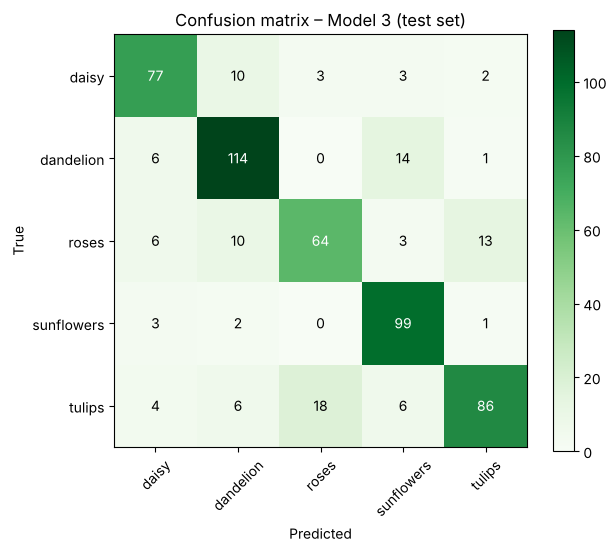

              precision    recall  f1-score   support

       daisy      0.802     0.811     0.806        95
   dandelion      0.803     0.844     0.823       135
       roses      0.753     0.667     0.707        96
  sunflowers      0.792     0.943     0.861       105
      tulips      0.835     0.717     0.771       120

    accuracy                          0.799       551
   macro avg      0.797     0.796     0.794       551
weighted avg      0.799     0.799     0.796       551



In [18]:
model3.eval()
all_preds, all_labels_, all_probs = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        out = model3(images.to(device))
        all_probs.append(F.softmax(out, 1).cpu())
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels_.extend(labels.numpy())
all_probs = torch.cat(all_probs)
all_preds, all_labels_ = np.array(all_preds), np.array(all_labels_)

cm = confusion_matrix(all_labels_, all_preds)
plt.figure(figsize=(6.5, 5.5))
plt.imshow(cm, cmap="Greens")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=45)
plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix – Model 3 (test set)")
plt.tight_layout(); plt.show()

print(classification_report(all_labels_, all_preds, target_names=class_names, digits=3))

### 9.2 Where does it make mistakes?

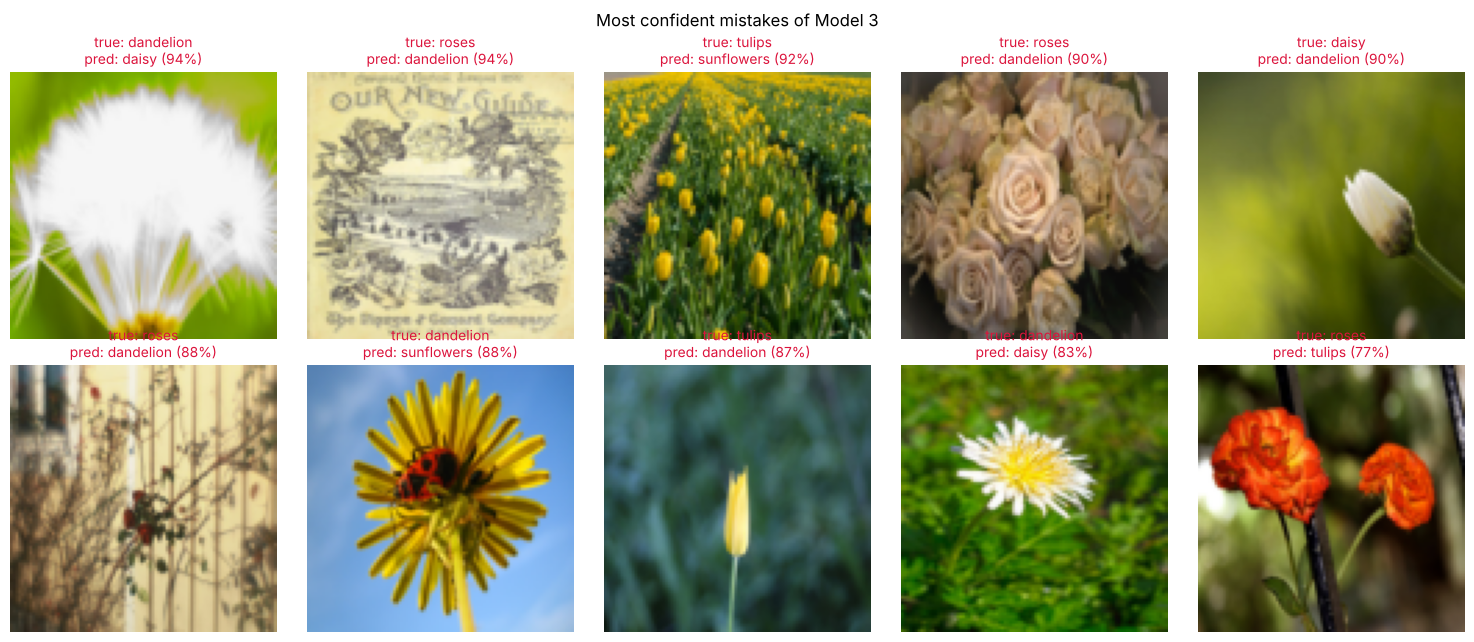

In [19]:
wrong = np.where(all_preds != all_labels_)[0]
conf = all_probs.max(1).values.numpy()
wrong = wrong[np.argsort(-conf[wrong])][:10]          # the most confident mistakes

plt.figure(figsize=(15, 6.5))
for k, w in enumerate(wrong):
    plt.subplot(2, 5, k + 1)
    plt.imshow(all_images[test_idx[w]].permute(1, 2, 0).numpy())
    plt.title(f"true: {class_names[all_labels_[w]]}\npred: {class_names[all_preds[w]]} ({conf[w]:.0%})",
              color="crimson", fontsize=10)
    plt.axis("off")
plt.suptitle("Most confident mistakes of Model 3")
plt.tight_layout(); plt.show()

### 9.3 Looking inside the CNN: learned filters & feature maps
A CNN learns its own feature extractors. The first layer learns simple **colour and edge detectors**; deeper layers combine
them into textures and flower parts.

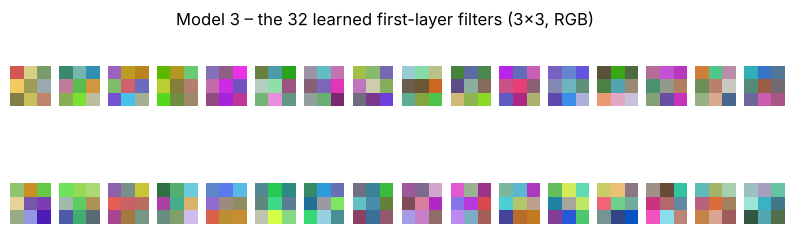

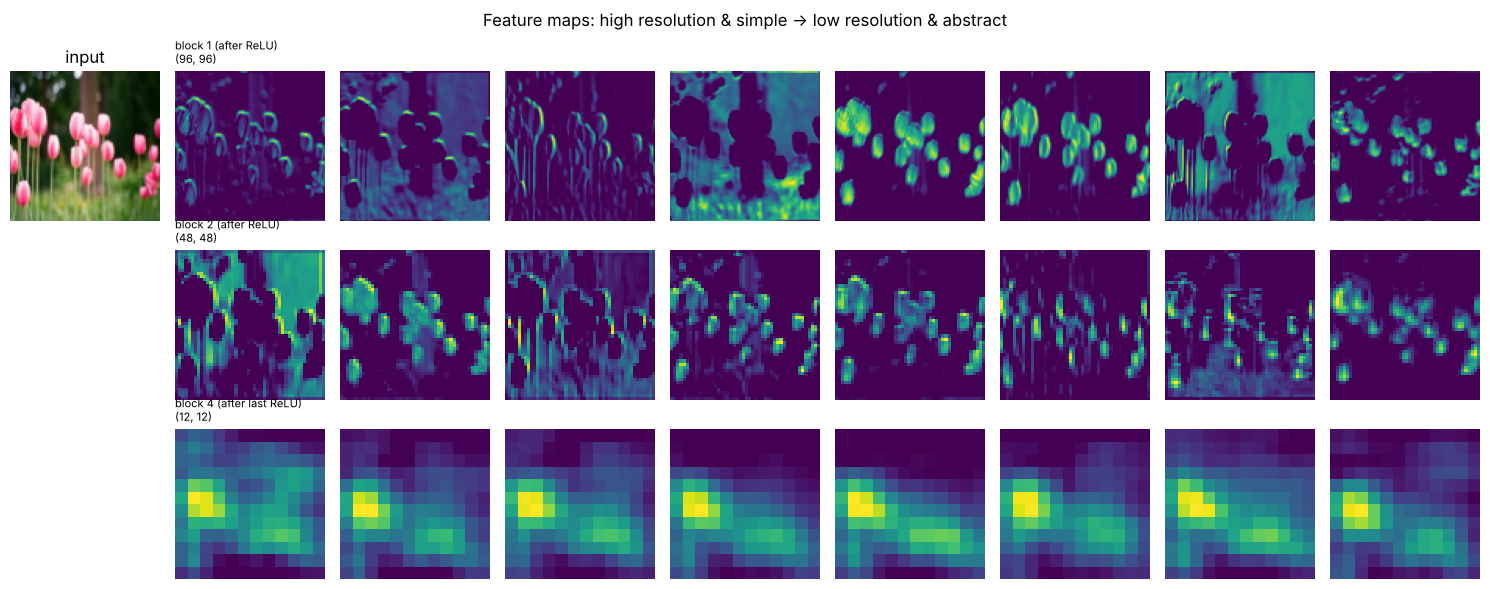

In [20]:
# first-layer filters (32 filters of size 3x3x3)
w = model3.features[0].weight.detach().cpu()
w = (w - w.min()) / (w.max() - w.min())
plt.figure(figsize=(10, 2.8))
for i in range(32):
    plt.subplot(2, 16, i + 1)
    plt.imshow(w[i].permute(1, 2, 0).numpy(), interpolation="nearest")
    plt.axis("off")
plt.suptitle("Model 3 – the 32 learned first-layer filters (3×3, RGB)")
plt.show()

# feature maps of one test image at 3 depths
img_u8 = all_images[test_idx[3]]
x = basic_transform(img_u8).unsqueeze(0).to(device)
layer_ids = {"block 1 (after ReLU)": 2, "block 2 (after ReLU)": 7, "block 4 (after last ReLU)": 23}
acts = {}
hooks = [model3.features[i].register_forward_hook(lambda m, inp, out, n=n: acts.__setitem__(n, out.detach().cpu()))
         for n, i in layer_ids.items()]
model3.eval()
with torch.no_grad():
    model3(x)
for h in hooks: h.remove()

plt.figure(figsize=(15, 6))
plt.subplot(3, 9, 1); plt.imshow(img_u8.permute(1, 2, 0).numpy()); plt.title("input"); plt.axis("off")
for r, (n, a) in enumerate(acts.items()):
    top = a[0].mean((1, 2)).argsort(descending=True)[:8]   # 8 most active channels
    for k, ch in enumerate(top):
        plt.subplot(3, 9, r * 9 + k + 2)
        plt.imshow(a[0, ch].numpy(), cmap="viridis"); plt.axis("off")
        if k == 0: plt.title(f"{n}\n{tuple(a.shape[2:])}", fontsize=8, loc="left")
plt.suptitle("Feature maps: high resolution & simple → low resolution & abstract")
plt.tight_layout(); plt.show()

### 9.4 Grad-CAM: *where* is the model looking?
Grad-CAM uses the gradients of the predicted class with respect to the last convolutional feature maps to build a heat-map
of the regions that influenced the decision. If the model learned real features (and did not memorise backgrounds),
the heat-map should be **on the flower**.

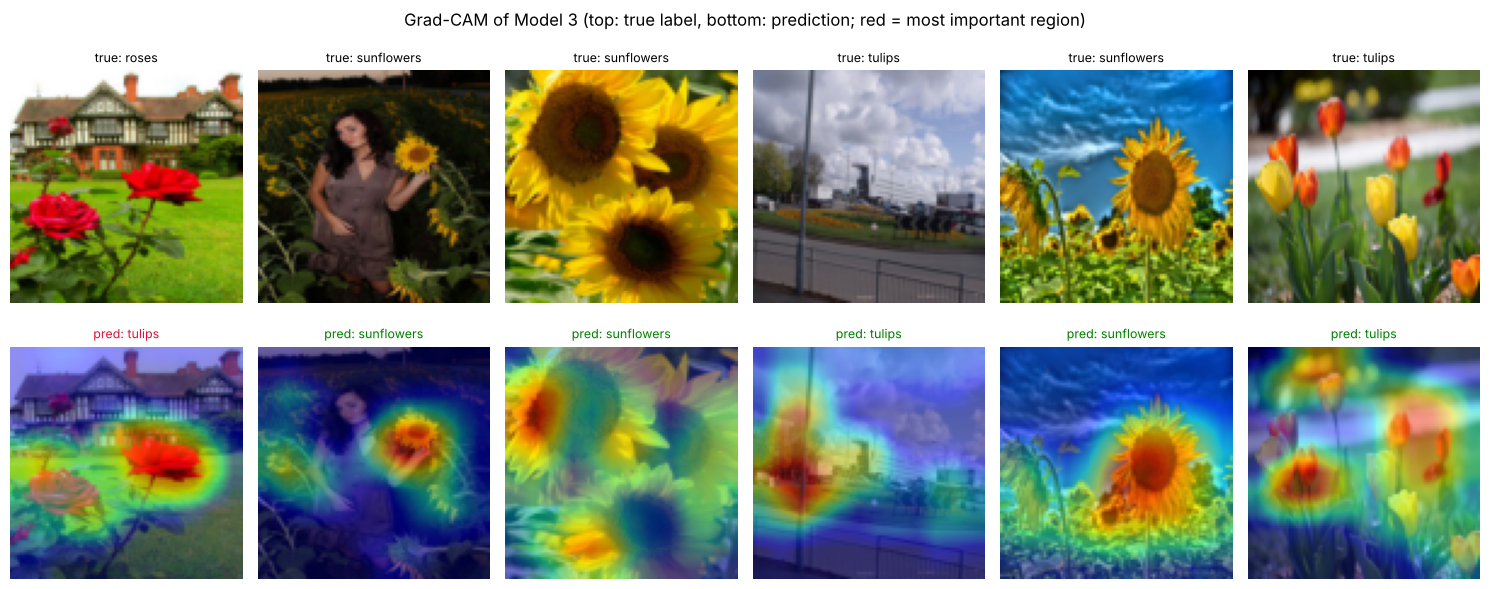

In [21]:
def grad_cam(model, img_u8, target_layer):
    feats, grads = {}, {}
    h1 = target_layer.register_forward_hook(lambda m, i, o: feats.__setitem__("v", o))
    h2 = target_layer.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("v", go[0]))
    model.eval()
    x = basic_transform(img_u8).unsqueeze(0).to(device)
    out = model(x)
    pred = out.argmax(1).item()
    model.zero_grad()
    out[0, pred].backward()
    h1.remove(); h2.remove()
    weights = grads["v"].mean(dim=(2, 3), keepdim=True)               # importance of each channel
    cam = F.relu((weights * feats["v"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=img_u8.shape[1:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), pred

target_layer = model3.features[23]          # last ReLU of the last conv block (12x12 maps)
picks = [test_idx[i] for i in np.random.default_rng(1).choice(len(test_idx), 6, replace=False)]
plt.figure(figsize=(15, 6.2))
for k, j in enumerate(picks):
    cam, pred = grad_cam(model3, all_images[j], target_layer)
    img = all_images[j].permute(1, 2, 0).numpy()
    plt.subplot(2, 6, k + 1); plt.imshow(img); plt.axis("off")
    plt.title(f"true: {class_names[all_labels[j]]}", fontsize=9)
    plt.subplot(2, 6, k + 7); plt.imshow(img); plt.imshow(cam, cmap="jet", alpha=0.45); plt.axis("off")
    plt.title(f"pred: {class_names[pred]}", fontsize=9,
              color="green" if pred == all_labels[j] else "crimson")
plt.suptitle("Grad-CAM of Model 3 (top: true label, bottom: prediction; red = most important region)")
plt.tight_layout(h_pad=2.0); plt.show()


**What Grad-CAM shows**
- On the sunflowers the heat-map sits **on the flower heads** – the woman in the 2nd photo is ignored and the model looks at the
  sunflower she is holding. So the network learned *flower features*, not backgrounds → another sign it is not memorising.
- On the tulips it looks at the **petal shapes**, even in the street photo where the tulips are a tiny strip.
- The mistake (first column: *roses* predicted as *tulips*) is understandable: the model looks at the right place (the red flower),
  but a red rose and a red tulip at 96×96 px look very similar. This matches the classification report, where **roses** and
  **tulips** have the lowest recall.


In [22]:
os.makedirs("checkpoints", exist_ok=True)
torch.save({"model_state": model3.state_dict(), "classes": class_names, "mean": MEAN, "std": STD,
            "img_size": IMG_SIZE}, "checkpoints/flowers_cnn_scratch.pt")
print("Saved best model to checkpoints/flowers_cnn_scratch.pt")

Saved best model to checkpoints/flowers_cnn_scratch.pt


## 10. Conclusion

| Model | Problem | Symptom | Fix applied |
|---|---|---|---|
| **1 – Tiny CNN** | **Underfitting** (high bias) | low train accuracy, train ≈ val (both bad) | ➜ more capacity: deeper & wider network, 3×3 convs, bigger head |
| **2 – Big CNN** | **Overfitting** (high variance) | train acc ≈ 100%, val loss rises after a few epochs, big gap | ➜ augmentation, BatchNorm, Dropout, Global Avg Pooling, weight decay, label smoothing, OneCycle LR, early stopping |
| **3 – Regularised CNN** | ✅ **Good fit** | val loss follows train loss, small gap, best test accuracy | — |

**What I learned**
1. Always look at the **loss curves**, not only the accuracy: the first sign of overfitting is the **validation loss going up**.
2. Measure the training accuracy in **eval mode without augmentation**, otherwise augmentation/dropout hide the real gap.
3. Underfitting and overfitting have **opposite** fixes: underfitting → *more* capacity / training; overfitting → *more*
   regularisation / data. Applying the wrong fix makes things worse.
4. With small datasets, **architecture choices** (Global Average Pooling instead of a huge FC layer) are as important as
   dropout: Model 3 has far fewer parameters than Model 2 and still generalises much better.
5. Augmentation must respect the problem: for flowers, **colour is part of the label**, so I changed brightness/contrast/
   saturation but **not hue**.

**Possible next steps:** a higher input resolution (128–160 px), MixUp/CutMix, test-time augmentation, or comparing with a
fine-tuned pretrained network (transfer learning).